=== Sensor Analyse ===
Kies 1 of 2.
Kies 1 of 2.
Kies 1 of 2.
Minimum moet kleiner zijn dan maximum
Opgeslagen in '1_readings.csv'.

--- Resultaten (2) ---
Aantal metingen      : 100
Gemiddelde           : 454.11
Minimum              : 401.32
Maximum              : 499.85
Standaardafwijking   : 30.05
Drempelwaarde        : 460.00
Boven drempelwaarde  : 46
Overschrijdingen     : #4 (460.39), #5 (462.57), #8 (483.75), #11 (499.56), #13 (483.65), #15 (463.91), #17 (463.49), #18 (486.80), #20 (474.13), #21 (467.14), #23 (475.82), #27 (486.55), #29 (471.88), #30 (487.88), #31 (471.41), #32 (492.11), #34 (480.09), #36 (493.56), #37 (487.89), #41 (496.55), #43 (462.66), #50 (490.42), #51 (468.20), #52 (492.89), #53 (485.64), #54 (499.10), #55 (467.13), #57 (486.06), #58 (496.46), #59 (490.47), #61 (471.38), #63 (483.16), #67 (485.39), #68 (498.98), #70 (480.06), #74 (476.88), #75 (487.28), #77 (461.45), #79 (471.84), #81 (488.09), #82 (498.06), #84 (499.85), #91 (461.05), #94 (486.78), #96 (4

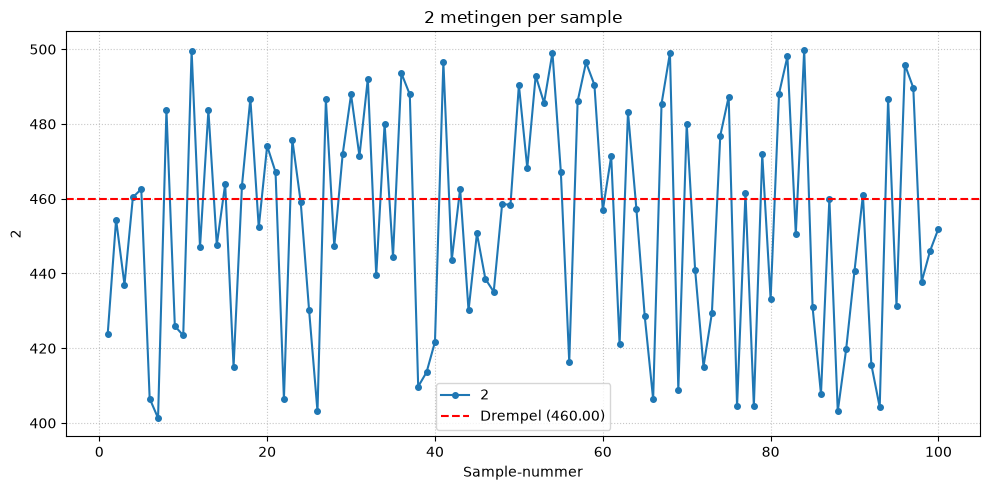

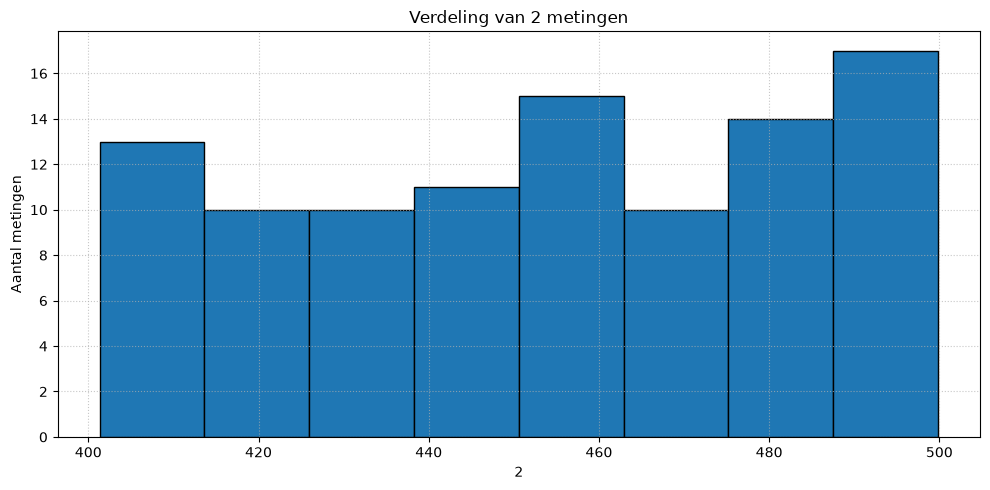

In [1]:
import csv
import os
import random
import matplotlib.pyplot as plt
import numpy as np


# ---------- Input helpers ----------

def prompt_int(message: str, min_value: int | None = None) -> int:
    """Blijf vragen totdat de gebruiker een geldig geheel getal invoert"""
    while True:
        try:
            value = int(input(message).strip())
        except ValueError:
            print("Voer een geheel getal in.")
            continue
        if min_value is not None and value < min_value:
            print(f"Waarde moet minimaal {min_value} zijn.")
            continue
        return value


def prompt_float(message: str) -> float:
    """Blijf vragen totdat de gebruiker een geldig geheel getal invoert"""
    while True:
        try:
            return float(input(message).strip().replace(",", "."))
        except ValueError:
            print("Voer een getal in.")


def prompt_seed(default: int = 42) -> int:
    """Vraag aan welke seed je wilt gebruiken, anders default"""
    while True:
        raw = input(f"Seed").strip()
        if not raw:
            return default
        try:
            return int(raw)
        except ValueError:
            print("Voer een geheel getal in of druk op Enter")


def get_user_input() -> tuple[str, int, float, float, float, int]:
    while True:
        sensor_type = input("Sensortype").strip()
        if sensor_type:
            break
        print("Sensortype mag niet leeg zijn")

    count = prompt_int("Aantal te genereren metingen", min_value=1)

    while True:
        min_val = prompt_float("Minimale sensorwaarde")
        max_val = prompt_float("Maximale sensorwaarde")
        if min_val < max_val:
            break
        print("Minimum moet kleiner zijn dan maximum")

    threshold = prompt_float("Waarschuwingsdrempel")
    seed = prompt_seed()
    return sensor_type, count, min_val, max_val, threshold, seed


# ---------- Data ----------

def generate_readings(count: int, min_val: float, max_val: float, seed: int = 42) -> np.ndarray:
    random.seed(seed)
    return np.array(
        [round(random.uniform(min_val, max_val), 2) for _ in range(count)],
        dtype=float,
    )


def load_readings(filepath: str) -> tuple[str, np.ndarray] | None:
    """Leest een CSV-bestand dat door"""
    try:
        with open(filepath, newline="", encoding="utf-8") as f:
            rows = list(csv.DictReader(f))
        if not rows:
            print("Het bestand bevat geen metingen")
            return None
        readings = np.array([float(row["reading"]) for row in rows], dtype=float)
        sensor_type = rows[0].get("sensor_type") or "sensor"
        return sensor_type, readings
    except OSError as exc:
        print(f"Fout bij lezen van '{filepath}': {exc}")
    except (KeyError, ValueError):
        print("Ongeldig CSV-formaat (verwacht kolommen: sample, reading, sensor_type)")
    return None


def save_readings(filepath: str, readings: np.ndarray, sensor_type: str) -> bool:
    try:
        folder = os.path.dirname(filepath)
        if folder:
            os.makedirs(folder, exist_ok=True)
        with open(filepath, mode="w", newline="", encoding="utf-8") as f:
            writer = csv.writer(f)
            writer.writerow(["sample", "reading", "sensor_type"])
            for idx, val in enumerate(readings, start=1):
                writer.writerow([idx, f"{float(val):.2f}", sensor_type])
        print(f"Opgeslagen in '{filepath}'.")
        return True
    except OSError as exc:
        print(f"Fout bij opslaan van '{filepath}': {exc}")
        return False


# ---------- analyse ----------

def calculate_statistics(readings: np.ndarray, threshold: float) -> dict[str, float | int]:
    return {
        "count": int(readings.size),
        "mean": float(np.mean(readings)),
        "min": float(np.min(readings)),
        "max": float(np.max(readings)),
        "std": float(np.std(readings)),
        "above_threshold": int(np.sum(readings > threshold)),
    }


def find_outliers(readings: np.ndarray, threshold: float) -> list[tuple[int, float]]:
    """Retuureer (sample number, value) Boven de treshhold."""
    return [(i, float(v)) for i, v in enumerate(readings, start=1) if v > threshold]


# ---------- Output ----------

def print_results(
    sensor_type: str,
    stats: dict[str, float | int],
    outliers: list[tuple[int, float]],
    threshold: float,
) -> None:
    print(f"\n--- Resultaten ({sensor_type}) ---")
    print(f"Aantal metingen      : {stats['count']}")
    print(f"Gemiddelde           : {stats['mean']:.2f}")
    print(f"Minimum              : {stats['min']:.2f}")
    print(f"Maximum              : {stats['max']:.2f}")
    print(f"Standaardafwijking   : {stats['std']:.2f}")
    print(f"Drempelwaarde        : {threshold:.2f}")
    print(f"Boven drempelwaarde  : {stats['above_threshold']}")
    if outliers:
        print("Overschrijdingen     : " + ", ".join(f"#{s} ({v:.2f})" for s, v in outliers))


def plot_readings(
    readings: np.ndarray,
    threshold: float,
    sensor_type: str,
    save_path: str = "readings_line_plot.png",
) -> None:
    samples = np.arange(1, readings.size + 1)
    plt.figure(figsize=(10, 5))
    plt.plot(samples, readings, marker="o", markersize=4, linewidth=1.5, label=sensor_type)
    plt.axhline(y=threshold, color="red", linestyle="--", linewidth=1.5, label=f"Drempel ({threshold:.2f})")
    plt.title(f"{sensor_type.capitalize()} metingen per sample")
    plt.xlabel("Sample-nummer")
    plt.ylabel(sensor_type.capitalize())
    plt.grid(True, linestyle=":", alpha=0.7)
    plt.legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)


def plot_histogram(
    readings: np.ndarray,
    sensor_type: str,
    save_path: str = "readings_histogram.png",
) -> None:
    plt.figure(figsize=(10, 5))
    plt.hist(readings, bins="auto", edgecolor="black")
    plt.title(f"Verdeling van {sensor_type} metingen")
    plt.xlabel(sensor_type.capitalize())
    plt.ylabel("Aantal metingen")
    plt.grid(True, linestyle=":", alpha=0.7)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)


# ---------- Main ----------

def main() -> None:
    print("=== Sensor Analyse ===")
    while True:
        choice = input("1 = Nieuwe metingen genereren | 2 = CSV inladen: ").strip()
        if choice in ("1", "2"):
            break
        print("Kies 1 of 2.")

    if choice == "1":
        sensor_type, count, min_val, max_val, threshold, seed = get_user_input()
        readings = generate_readings(count, min_val, max_val, seed=seed)
        default_csv = f"{sensor_type.lower().replace(' ', '_')}_readings.csv"
        filepath = input(f"CSV-bestandsnaam (Enter voor '{default_csv}'): ").strip() or default_csv
        save_readings(filepath, readings, sensor_type)
    else:
        while True:
            loaded = load_readings(input(" je CSV-bestand ").strip())
            if loaded:
                default_type, readings = loaded
                sensor_type = input(f"Sensortype").strip() or default_type
                threshold = prompt_float("Waarschuwingsdrempel")
                break

    stats = calculate_statistics(readings, threshold)
    outliers = find_outliers(readings, threshold)
    print_results(sensor_type, stats, outliers, threshold)
    plot_readings(readings, threshold, sensor_type)
    plot_histogram(readings, sensor_type)
    plt.show()


if __name__ == "__main__":
    main()